In [ ]:
import os

from google.colab import drive
drive.mount('/content/drive')

print("Google Drive folders:")
print(os.listdir('/content/drive/MyDrive'))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive folders:
['PARNASHREE_SINHA_BWU_MCA_25_234.pdf', 'PARNASHREE_SINHA_BWU_MCA_25_234 (1).pdf', 'compressed_1000222608.pdf', '+91 8293667735_compressed (1).pdf', '+91 8293667735_compressed.pdf', 'IMG_20260112_213203-compressed_compressed.pdf', 'IMG-20251117-WA0000.jpg', '1000173308.pdf', '1000229716.pdf', 'Trojans.pdf', '9d3fbe63-d6e9-4cb5-a081-ebf7977c0fef.pptx', 'AI_Module3_Presentation.pptx', 'BWU AI Mod 3 Project Documentation.pdf', 'BWU AI Mod 1 Project Documentation.pdf', 'MyCV (1).pdf', 'CV_ParnashreeSinha_MCA_234 (2).pdf', 'CV_ParnashreeSinha.pdf', '26.05.2026_17.27.08_REC.png', 'photo_2026-05-26_17-46-28.jpg', 'Document from Anubhab.gdoc', 'ss.png', 'mail.png', 'Screenshot_2026_0605_223014.jpg', 'WhatsApp Image 2026-06-05 at 10.30.27 PM.jpeg', 'Colab Notebooks', 'CV_ParnashreeSinha_MCA_234 (1).pdf', 'CV_ParnashreeSinha_MCA_234.pdf', 'Lec 38.

In [ ]:
import os

project_path = "/content/drive/MyDrive/Network_Intrusion_Detection"

print("Project folder contents:\n")

for item in os.listdir(project_path):
    print(item)


Project folder contents:

UNSW_NB15_testing-set.csv
UNSW_NB15_training-set.csv
best_intrusion_detection_model.pkl
app.py


-----Load the Dataset-----

In [ ]:
import pandas as pd
import numpy as np

project_path = "/content/drive/MyDrive/Network_Intrusion_Detection"

# Load training dataset
train_df = pd.read_csv(
    project_path + "/UNSW_NB15_training-set.csv"
)

# Load testing dataset
test_df = pd.read_csv(
    project_path + "/UNSW_NB15_testing-set.csv"
)

print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

print("\nTraining Dataset Preview:")
display(train_df.head())

print("\nTesting Dataset Preview:")
display(test_df.head())


Training Dataset Shape: (175341, 45)
Testing Dataset Shape: (82332, 45)

Training Dataset Preview:


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0



Testing Dataset Preview:


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,...,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,...,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,...,1,3,0,0,0,1,3,0,Normal,0
3,4,0.000006,udp,-,INT,2,0,900,0,166666.6608,...,1,3,0,0,0,2,3,0,Normal,0
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.0025,...,1,3,0,0,0,2,3,0,Normal,0


In [ ]:
# 1. Display all column names and data types

print("DATASET INFORMATION")
print("-" * 50)

train_df.info()


# 2. Check missing values

print("\nMISSING VALUES")
print("-" * 50)

print(train_df.isnull().sum().sort_values(ascending=False))


# 3. Check duplicate records

print("\nDUPLICATE RECORDS")
print("-" * 50)

print("Training duplicates:", train_df.duplicated().sum())
print("Testing duplicates:", test_df.duplicated().sum())


# 4. Check target distribution

print("\nBINARY TARGET DISTRIBUTION")
print("-" * 50)

print(train_df['label'].value_counts())

print("\nAttack Category Distribution")
print("-" * 50)

print(train_df['attack_cat'].value_counts())


DATASET INFORMATION
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  object 
 3   service            175341 non-null  object 
 4   state              175341 non-null  object 
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non

-----Exploratory Data Analysis(EDA)-----

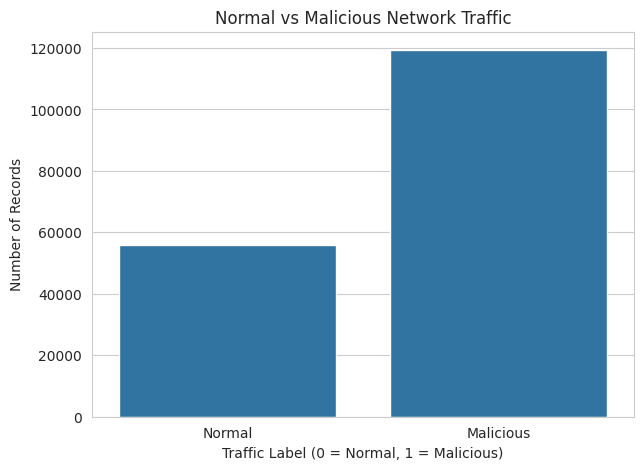

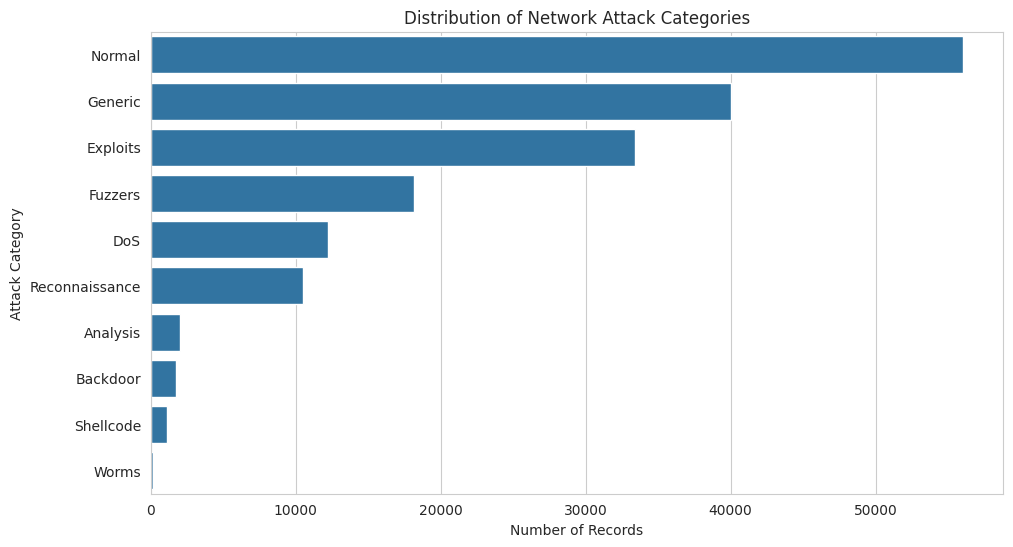

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# Graph 1: Normal vs Malicious Traffic

plt.figure(figsize=(7, 5))

sns.countplot(
    data=train_df,
    x='label'
)

plt.title("Normal vs Malicious Network Traffic")
plt.xlabel("Traffic Label (0 = Normal, 1 = Malicious)")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ['Normal', 'Malicious'])

plt.show()


# Graph 2: Attack Category Distribution

plt.figure(figsize=(11, 6))

sns.countplot(
    data=train_df,
    y='attack_cat',
    order=train_df['attack_cat'].value_counts().index
)

plt.title("Distribution of Network Attack Categories")
plt.xlabel("Number of Records")
plt.ylabel("Attack Category")

plt.show()


-----Analyzing numerical and categorical features-----

In [ ]:

# Numerical feature summary

print("NUMERICAL FEATURE SUMMARY")
display(train_df.describe())


# Categorical feature summary

print("\nCATEGORICAL FEATURE SUMMARY")

categorical_cols = train_df.select_dtypes(
    include=['object']
).columns

display(train_df[categorical_cols].describe())


# Unique values in categorical columns

print("\nUNIQUE VALUES")

for col in categorical_cols:
    print(f"{col}: {train_df[col].nunique()} unique values")
    print(train_df[col].unique()[:15])


NUMERICAL FEATURE SUMMARY


,id,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,label
count,175341.000000,175341.000000,175341.000000,175341.000000,1.753410e+05,1.753410e+05,1.753410e+05,175341.000000,175341.000000,1.753410e+05,...,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000
mean,87671.000000,1.359389,20.298664,18.969591,8.844844e+03,1.492892e+04,9.540619e+04,179.546997,79.609567,7.345403e+07,...,5.383538,4.206255,8.729881,0.014948,0.014948,0.133066,6.955789,9.100758,0.015752,0.680622
std,50616.731112,6.480249,136.887597,110.258271,1.747656e+05,1.436542e+05,1.654010e+05,102.940011,110.506863,1.883574e+08,...,8.047104,5.783585,10.956186,0.126048,0.126048,0.701208,8.321493,10.756952,0.124516,0.466237
min,1.000000,0.000000,1.000000,0.000000,2.800000e+01,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,43836.000000,0.000008,2.000000,0.000000,1.140000e+02,0.000000e+00,3.278614e+01,62.000000,0.000000,1.305334e+04,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,0.000000
50%,87671.000000,0.001582,2.000000,2.000000,4.300000e+02,1.640000e+02,3.225807e+03,254.000000,29.000000,8.796748e+05,...,1.000000,1.000000,3.000000,0.000000,0.000000,0.000000,3.000000,4.000000,0.000000,1.000000
75%,131506.000000,0.668069,12.000000,10.000000,1.418000e+03,1.102000e+03,1.250000e+05,254.000000,252.000000,8.888889e+07,...,5.000000,3.000000,12.000000,0.000000,0.000000,0.000000,9.000000,12.000000,0.000000,1.000000
max,175341.000000,59.999989,9616.000000,10974.000000,1.296523e+07,1.465555e+07,1.000000e+06,255.000000,254.000000,5.988000e+09,...,51.000000,46.000000,65.000000,4.000000,4.000000,30.000000,60.000000,62.000000,1.000000,1.000000



CATEGORICAL FEATURE SUMMARY


,proto,service,state,attack_cat
count,175341,175341,175341,175341
unique,133,13,9,10
top,tcp,-,INT,Normal
freq,79946,94168,82275,56000



UNIQUE VALUES
proto: 133 unique values
['tcp' 'udp' 'arp' 'ospf' 'icmp' 'igmp' 'rtp' 'ddp' 'ipv6-frag' 'cftp'
 'wsn' 'pvp' 'wb-expak' 'mtp' 'pri-enc']
service: 13 unique values
['-' 'ftp' 'smtp' 'snmp' 'http' 'ftp-data' 'dns' 'ssh' 'radius' 'pop3'
 'dhcp' 'ssl' 'irc']
state: 9 unique values
['FIN' 'INT' 'CON' 'ECO' 'REQ' 'RST' 'PAR' 'URN' 'no']
attack_cat: 10 unique values
['Normal' 'Backdoor' 'Analysis' 'Fuzzers' 'Shellcode' 'Reconnaissance'
 'Exploits' 'DoS' 'Worms' 'Generic']


-----Visualizing numerical features-----

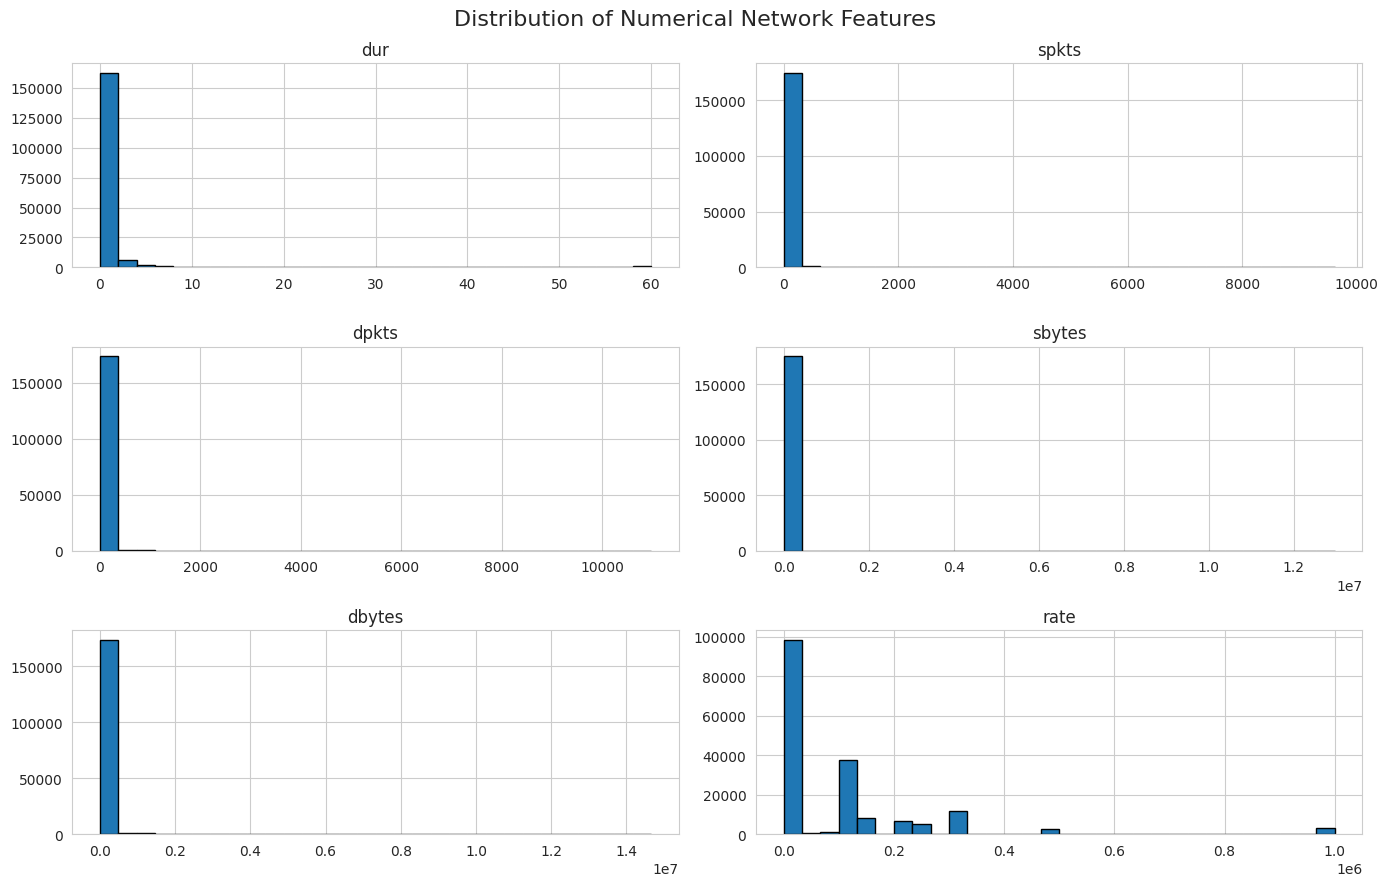

In [ ]:

# Select important numerical features

numerical_features = [
    'dur',
    'spkts',
    'dpkts',
    'sbytes',
    'dbytes',
    'rate'
]

# Plot histograms

train_df[numerical_features].hist(
    figsize=(14, 9),
    bins=30,
    edgecolor='black'
)

plt.suptitle(
    "Distribution of Numerical Network Features",
    fontsize=16
)

plt.tight_layout()
plt.show()


-----Correlation analysis-----

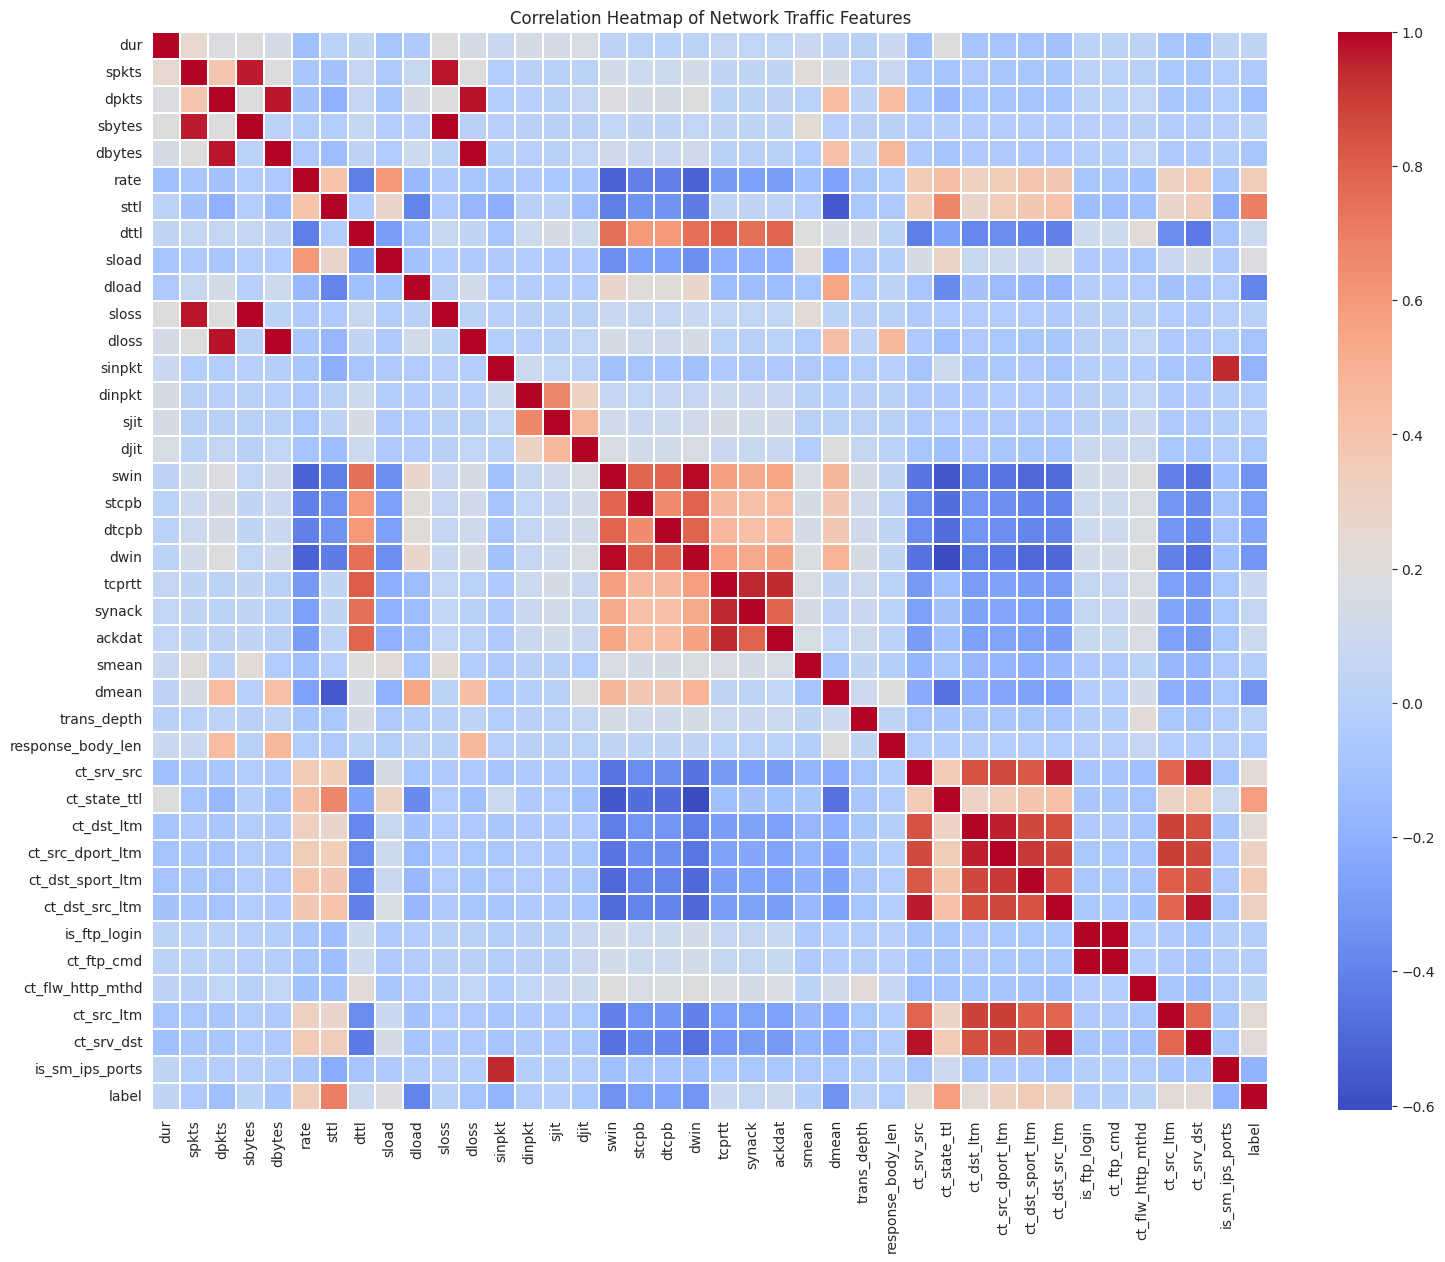

In [ ]:
# Calculate correlation between numerical columns

correlation = train_df.select_dtypes(
    include=['int64', 'float64']
).drop(columns=['id']).corr()

# Display correlation heatmap

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    linewidths=0.2
)

plt.title("Correlation Heatmap of Network Traffic Features")
plt.show()


In [ ]:
# Separate input features and target

X_train = train_df.drop(
    columns=['id', 'attack_cat', 'label']
)

y_train = train_df['label']

X_test = test_df.drop(
    columns=['id', 'attack_cat', 'label']
)

y_test = test_df['label']


# Check dataset dimensions

print("Training Features Shape:", X_train.shape)
print("Training Target Shape:", y_train.shape)

print("\nTesting Features Shape:", X_test.shape)
print("Testing Target Shape:", y_test.shape)


# Check target distribution

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())


Training Features Shape: (175341, 42)
Training Target Shape: (175341,)

Testing Features Shape: (82332, 42)
Testing Target Shape: (82332,)

Training Target Distribution:
label
1    119341
0     56000
Name: count, dtype: int64

Testing Target Distribution:
label
1    45332
0    37000
Name: count, dtype: int64


In [ ]:
# Identify numerical and categorical columns

numerical_cols = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=['object']
).columns.tolist()


print("Numerical Features:", len(numerical_cols))
print(numerical_cols)

print("\nCategorical Features:", len(categorical_cols))
print(categorical_cols)


Numerical Features: 39
['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']

Categorical Features: 3
['proto', 'service', 'state']


In [ ]:

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Numerical preprocessing
numerical_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

# Combine both preprocessing methods
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [ ]:
# Fit preprocessing on training data and transform it
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the same fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

# Check the results
print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

print("\nPreprocessing completed successfully!")


Training data after preprocessing: (175341, 194)
Testing data after preprocessing: (82332, 194)

Preprocessing completed successfully!


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All machine learning libraries imported successfully!")


All machine learning libraries imported successfully!


In [ ]:
# Create Logistic Regression model

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_processed, y_train)

print("Logistic Regression training completed!")

# Make predictions on testing data
lr_predictions = lr_model.predict(X_test_processed)

print("\nFirst 10 Predictions:")
print(lr_predictions[:10])


Logistic Regression training completed!

First 10 Predictions:
[1 1 1 1 1 1 1 1 0 0]


LOGISTIC REGRESSION EVALUATION
----------------------------------------
Accuracy : 0.8097
Precision: 0.7535
Recall   : 0.9725
F1 Score : 0.8491

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.95      0.61      0.74     37000
           1       0.75      0.97      0.85     45332

    accuracy                           0.81     82332
   macro avg       0.85      0.79      0.80     82332
weighted avg       0.84      0.81      0.80     82332



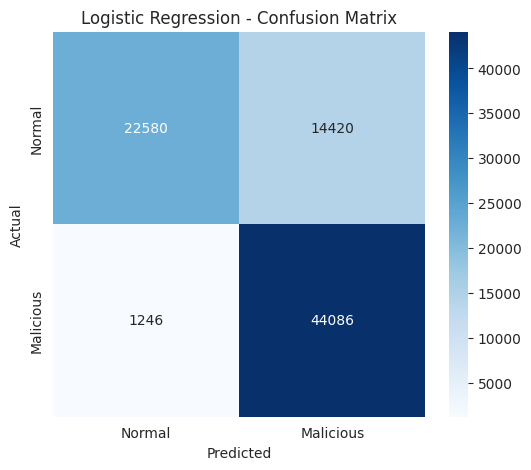

In [ ]:
# Evaluate Logistic Regression

lr_accuracy = accuracy_score(y_test, lr_predictions)

lr_precision = precision_score(
    y_test, lr_predictions
)

lr_recall = recall_score(
    y_test, lr_predictions
)

lr_f1 = f1_score(
    y_test, lr_predictions
)

print("LOGISTIC REGRESSION EVALUATION")
print("-" * 40)

print("Accuracy :", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1 Score :", round(lr_f1, 4))


# Classification Report

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, lr_predictions))


# Confusion Matrix

cm = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Malicious'],
    yticklabels=['Normal', 'Malicious']
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()


In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train_processed, y_train)

dt_predictions = dt_model.predict(X_test_processed)

print("Decision Tree training completed!")

print("\nFirst 10 Predictions:")
print(dt_predictions[:10])

Decision Tree training completed!

First 10 Predictions:
[0 0 1 1 1 0 1 1 0 0]


DECISION TREE EVALUATION
----------------------------------------
Accuracy : 0.8636
Precision: 0.8243
Recall   : 0.956
F1 Score : 0.8853

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.93      0.75      0.83     37000
           1       0.82      0.96      0.89     45332

    accuracy                           0.86     82332
   macro avg       0.88      0.85      0.86     82332
weighted avg       0.87      0.86      0.86     82332



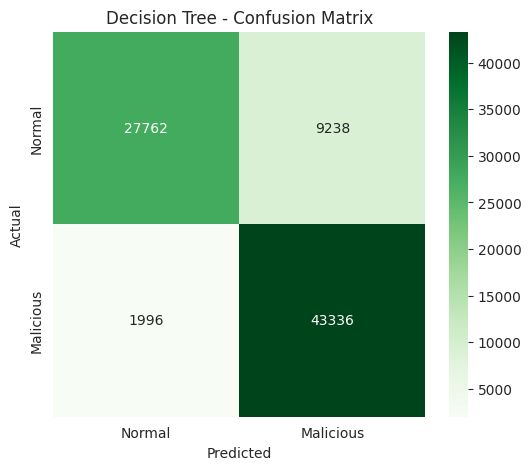

In [ ]:
dt_accuracy = accuracy_score(y_test, dt_predictions)
dt_precision = precision_score(y_test, dt_predictions)
dt_recall = recall_score(y_test, dt_predictions)
dt_f1 = f1_score(y_test, dt_predictions)

print("DECISION TREE EVALUATION")
print("-" * 40)
print("Accuracy :", round(dt_accuracy, 4))
print("Precision:", round(dt_precision, 4))
print("Recall   :", round(dt_recall, 4))
print("F1 Score :", round(dt_f1, 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, dt_predictions))

cm = confusion_matrix(y_test, dt_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Normal', 'Malicious'],
    yticklabels=['Normal', 'Malicious']
)
plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

rf_predictions = rf_model.predict(X_test_processed)

print("Random Forest training completed!")

print("\nFirst 10 Predictions:")
print(rf_predictions[:10])

Random Forest training completed!

First 10 Predictions:
[1 1 1 1 1 1 1 1 0 0]


RANDOM FOREST EVALUATION
----------------------------------------
Accuracy : 0.8711
Precision: 0.8178
Recall   : 0.9854
F1 Score : 0.8938

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.98      0.73      0.84     37000
           1       0.82      0.99      0.89     45332

    accuracy                           0.87     82332
   macro avg       0.90      0.86      0.86     82332
weighted avg       0.89      0.87      0.87     82332



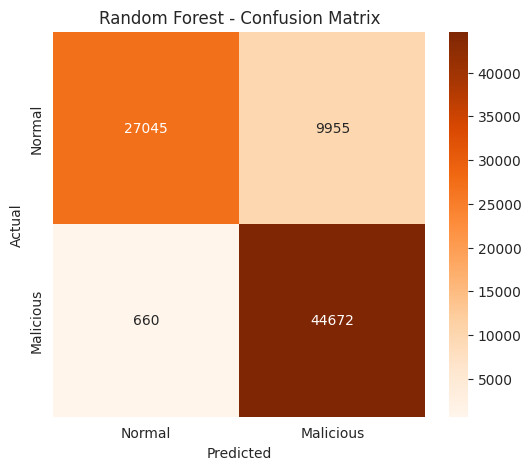

In [ ]:
rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_precision = precision_score(y_test, rf_predictions)
rf_recall = recall_score(y_test, rf_predictions)
rf_f1 = f1_score(y_test, rf_predictions)

print("RANDOM FOREST EVALUATION")
print("-" * 40)
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, rf_predictions))

cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Normal', 'Malicious'],
    yticklabels=['Normal', 'Malicious']
)
plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

print("Cross-validation tools imported successfully!")

Cross-validation tools imported successfully!


In [ ]:
# Logistic Regression Pipeline
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Decision Tree Pipeline
dt_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        random_state=42
    ))
])

# Random Forest Pipeline
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

print("All three ML pipelines created successfully!")

All three ML pipelines created successfully!


In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-Fold Stratified Cross-Validation configured!")

5-Fold Stratified Cross-Validation configured!


In [ ]:
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

print("Cross-validation evaluation metrics configured!")

Cross-validation evaluation metrics configured!


In [ ]:
import pandas as pd

cv_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy': [
        lr_cv_results['test_accuracy'].mean(),
        dt_cv_results['test_accuracy'].mean(),
        rf_cv_results['test_accuracy'].mean()
    ],
    'Precision': [
        lr_cv_results['test_precision'].mean(),
        dt_cv_results['test_precision'].mean(),
        rf_cv_results['test_precision'].mean()
    ],
    'Recall': [
        lr_cv_results['test_recall'].mean(),
        dt_cv_results['test_recall'].mean(),
        rf_cv_results['test_recall'].mean()
    ],
    'F1 Score': [
        lr_cv_results['test_f1'].mean(),
        dt_cv_results['test_f1'].mean(),
        rf_cv_results['test_f1'].mean()
    ]
})

print("5-FOLD CROSS-VALIDATION RESULTS")
display(cv_comparison.round(4))

In [ ]:
from sklearn.model_selection import GridSearchCV

print("GridSearchCV imported successfully!")

In [ ]:
rf_param_grid = {
    'classifier__n_estimators': [100, 150],
    'classifier__max_depth': [None, 20],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2]
}

print("Random Forest parameter grid created!")

In [ ]:
rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=1,
    verbose=2
)

print("Random Forest GridSearchCV configured!")

In [ ]:
from sklearn.model_selection import train_test_split

X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Tuning dataset prepared!")
print("Tuning records:", X_tune.shape[0])

In [ ]:
fast_param_grid = {
    'classifier__n_estimators': [100, 150],
    'classifier__max_depth': [20]
}

fast_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

fast_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=fast_param_grid,
    cv=fast_cv,
    scoring='f1',
    n_jobs=1,
    verbose=1
)

print("Fast GridSearchCV configured!")

In [ ]:
fast_grid_search.fit(X_tune, y_tune)

print("Fast Hyperparameter Tuning Completed!")

print("\nBest Parameters:")
print(fast_grid_search.best_params_)

print("\nBest F1 Score:")
print(round(fast_grid_search.best_score_, 4))

In [ ]:
print("Best Parameters:")
print(fast_grid_search.best_params_)

print("\nBest F1 Score:")
print(round(fast_grid_search.best_score_, 4))

In [ ]:
best_rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=150,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    ))
])

best_rf_pipeline.fit(X_train, y_train)

print("Final tuned Random Forest trained successfully!")

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

final_predictions = best_rf_pipeline.predict(X_test)

print("FINAL TUNED RANDOM FOREST EVALUATION")
print("-" * 45)

print("Accuracy :", round(accuracy_score(y_test, final_predictions), 4))
print("Precision:", round(precision_score(y_test, final_predictions), 4))
print("Recall   :", round(recall_score(y_test, final_predictions), 4))
print("F1 Score :", round(f1_score(y_test, final_predictions), 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, final_predictions))

In [ ]:
cm = confusion_matrix(y_test, final_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Malicious'],
    yticklabels=['Normal', 'Malicious']
)

plt.title("Tuned Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
import joblib
import os

model_path = os.path.join(
    project_path,
    "best_intrusion_detection_model.pkl"
)

joblib.dump(rf_pipeline, model_path)

print("Model saved successfully!")
print("Saved location:", model_path)

In [ ]:
loaded_model = joblib.load(model_path)

print("Saved model loaded successfully!")

In [ ]:
# Train the Random Forest pipeline on the full training dataset
rf_pipeline.fit(X_train, y_train)

print("Final Random Forest model trained successfully!")

In [ ]:
# Save the trained model
joblib.dump(rf_pipeline, model_path)

print("Trained model saved successfully!")
print("Location:", model_path)

In [ ]:
# Load the corrected trained model
loaded_model = joblib.load(model_path)

# Select 5 unseen records
new_records = X_test.iloc[:5]

# Predict network traffic
new_predictions = loaded_model.predict(new_records)

print("UNSEEN NETWORK TRAFFIC PREDICTIONS")
print("-" * 40)

for i, prediction in enumerate(new_predictions):
    result = "Malicious Traffic" if prediction == 1 else "Normal Traffic"
    print(f"Record {i+1}: {result}")

In [ ]:
# Compare predicted labels with actual labels
actual_labels = y_test.iloc[:5].values

print("PREDICTION VERIFICATION")
print("-" * 40)

for i in range(5):
    actual = "Malicious" if actual_labels[i] == 1 else "Normal"
    predicted = "Malicious" if new_predictions[i] == 1 else "Normal"

    status = "Correct" if actual_labels[i] == new_predictions[i] else "Incorrect"

    print(f"Record {i+1}: Actual = {actual} | Predicted = {predicted} | {status}")

In [ ]:
# Check 20 unseen records
sample_records = X_test.iloc[:20]
sample_actual = y_test.iloc[:20].values

sample_predictions = loaded_model.predict(sample_records)

correct = sum(sample_actual == sample_predictions)
incorrect = len(sample_actual) - correct

print("PREDICTION SUMMARY")
print("-" * 35)
print("Total Records:", len(sample_actual))
print("Correct Predictions:", correct)
print("Incorrect Predictions:", incorrect)
print("Sample Accuracy:", round(correct / len(sample_actual) * 100, 2), "%")

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predict the complete testing dataset
all_predictions = loaded_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, all_predictions)

print("SAVED MODEL - COMPLETE TEST RESULTS")
print("-" * 45)
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, all_predictions))

print("Confusion Matrix:")
print(confusion_matrix(y_test, all_predictions))

In [ ]:
# Select 5 unseen network records
new_records = X_test.iloc[:5]

# Predict using the saved model
new_predictions = loaded_model.predict(new_records)

print("UNSEEN NETWORK TRAFFIC PREDICTIONS")
print("-" * 40)

for i, prediction in enumerate(new_predictions):
    if prediction == 1:
        result = "Malicious Traffic"
    else:
        result = "Normal Traffic"

    print(f"Record {i+1}: {result}")

In [ ]:
# Install Streamlit
!pip install streamlit -q

print("Streamlit installed successfully!")

In [ ]:
%%writefile /content/drive/MyDrive/Network_Intrusion_Detection/app.py

import streamlit as st
import pandas as pd
import joblib
import os

# Page configuration
st.set_page_config(
    page_title="Network Intrusion Detection",
    page_icon="🛡️",
    layout="wide"
)

# Load trained model
project_path = "/content/drive/MyDrive/Network_Intrusion_Detection"
model_path = os.path.join(project_path, "best_intrusion_detection_model.pkl")

model = joblib.load(model_path)

# Application title
st.title("🛡️ Network Intrusion Detection System")
st.write("Machine Learning Based Network Traffic Classification")

st.info("Upload a network traffic CSV file to detect normal and malicious traffic.")

# Upload CSV
uploaded_file = st.file_uploader(
    "Upload Network Traffic CSV",
    type=["csv"]
)

if uploaded_file is not None:

    data = pd.read_csv(uploaded_file)

    st.subheader("Uploaded Dataset")
    st.dataframe(data.head())

    # Remove unnecessary columns if present
    input_data = data.drop(
        columns=["id", "attack_cat", "label"],
        errors="ignore"
    )

    if st.button("Detect Intrusions"):

        try:
            predictions = model.predict(input_data)

            results = data.copy()

            results["Prediction"] = [
                "Malicious Traffic" if p == 1 else "Normal Traffic"
                for p in predictions
            ]

            st.subheader("Detection Results")
            st.dataframe(results)

            malicious_count = sum(predictions == 1)
            normal_count = sum(predictions == 0)

            col1, col2 = st.columns(2)

            col1.metric("Malicious Traffic", malicious_count)
            col2.metric("Normal Traffic", normal_count)

            # Download results
            csv = results.to_csv(index=False).encode("utf-8")

            st.download_button(
                "Download Prediction Results",
                data=csv,
                file_name="intrusion_detection_results.csv",
                mime="text/csv"
            )

        except Exception as e:
            st.error(f"Prediction error: {e}")

In [ ]:
print("Model loaded:", 'loaded_model' in globals())
print("Uploaded files:", upload.value)

In [ ]:
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output

upload = widgets.FileUpload(
    accept='.csv',
    multiple=False,
    description='Upload CSV'
)

button = widgets.Button(
    description='Detect Intrusions',
    button_style='success'
)

output = widgets.Output()

def detect_intrusions(b):
    with output:
        clear_output()

        if not upload.value:
            print("Please upload a CSV file first.")
            return

        file_info = upload.value

        if isinstance(file_info, dict):
            file_info = list(file_info.values())[0]
            content = file_info['content']
        else:
            content = file_info[0]['content']

        import io
        data = pd.read_csv(io.BytesIO(content))

        input_data = data.drop(
            columns=['id', 'attack_cat', 'label'],
            errors='ignore'
        )

        predictions = loaded_model.predict(input_data)

        results = data.copy()
        results['Prediction'] = [
            'Malicious Traffic' if p == 1 else 'Normal Traffic'
            for p in predictions
        ]

        print("Detection Completed!")
        print("Total Records:", len(results))
        print("Malicious:", sum(predictions == 1))
        print("Normal:", sum(predictions == 0))

        display(results.head(20))

        from IPython.display import FileLink
        results.to_csv(
            'intrusion_detection_results.csv',
            index=False
        )

        display(FileLink('intrusion_detection_results.csv'))

display(widgets.HTML(
    "<h2>🛡️ Network Intrusion Detection System</h2>"
    "<p>Upload network traffic data to detect malicious activity.</p>"
))
display(upload, button, output)

button.on_click(detect_intrusions)

In [ ]:
print("Model loaded:", 'loaded_model' in globals())
print("Uploaded files:", upload.value)

In [111]:
import pandas as pd

test_data = pd.read_csv(
    "/content/drive/MyDrive/Network_Intrusion_Detection/UNSW_NB15_testing-set.csv"
)

X_test_final = test_data.drop(
    columns=["id", "attack_cat", "label"],
    errors="ignore"
)

predictions = loaded_model.predict(X_test_final)

results = test_data.copy()
results["Prediction"] = [
    "Malicious Traffic" if p == 1 else "Normal Traffic"
    for p in predictions
]

print("Detection completed!")
print("Total records:", len(results))
print("Malicious traffic:", sum(predictions == 1))
print("Normal traffic:", sum(predictions == 0))

display(results.head(10))

Detection completed!
Total records: 82332
Malicious traffic: 54627
Normal traffic: 27705


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label,Prediction
0,1,0.000011,udp,-,INT,2,0,496,0,90909.09020,...,2,0,0,0,1,2,0,Normal,0,Malicious Traffic
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.00030,...,2,0,0,0,1,2,0,Normal,0,Malicious Traffic
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.00510,...,3,0,0,0,1,3,0,Normal,0,Malicious Traffic
3,4,0.000006,udp,-,INT,2,0,900,0,166666.66080,...,3,0,0,0,2,3,0,Normal,0,Malicious Traffic
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.00250,...,3,0,0,0,2,3,0,Normal,0,Malicious Traffic
5,6,0.000003,udp,-,INT,2,0,784,0,333333.32150,...,2,0,0,0,2,2,0,Normal,0,Malicious Traffic
6,7,0.000006,udp,-,INT,2,0,1960,0,166666.66080,...,2,0,0,0,2,2,0,Normal,0,Malicious Traffic
7,8,0.000028,udp,-,INT,2,0,1384,0,35714.28522,...,3,0,0,0,1,3,0,Normal,0,Malicious Traffic
8,9,0.000000,arp,-,INT,1,0,46,0,0.00000,...,2,0,0,0,2,2,1,Normal,0,Normal Traffic
9,10,0.000000,arp,-,INT,1,0,46,0,0.00000,...,2,0,0,0,2,2,1,Normal,0,Normal Traffic


In [112]:
results.to_csv(
    "/content/drive/MyDrive/Network_Intrusion_Detection/intrusion_detection_results.csv",
    index=False
)

print("Prediction results saved successfully!")

Prediction results saved successfully!
